# Modularity in the Karate Club Graph
**DSC212: Graph Theory — Research Assignment**
<br>

**Name:** Ayush Mhaisalkar
<br>
**Roll no.:** IMS25251
<br>
<br>

This file uses spectral modularity to divide the Karate Club graph into communities.

> **AI-use note:** I have used AI to write and debug parts of this code. The notebook was run and the results were checked by me.

**Reference:** M. E. J. Newman (2006), *Modularity and community structure in networks*, PNAS 103(23), 8577–8582.

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
np.set_printoptions(precision=4, suppress=True)
print("networkx", nx.__version__, "| numpy", np.__version__)

networkx 3.6.1 | numpy 2.3.5


## 1. Data and modularity

The modularity matrix is

$
B = A - \frac{k k^\top}{2m}, \qquad Q = \frac{1}{4m} s^\top B s.
$

The checks below confirm that $B$ is symmetric and that $B\mathbf{1}=0$.


In [ ]:
G = nx.karate_club_graph()                 # 34 nodes, 78 edges; node ids are 0..33 (Zachary's numbering minus 1)
nx.set_edge_attributes(G, 1, "weight")     # newer NetworkX versions ship Zachary's interaction counts as weights; use the plain 0/1 graph
nodes = sorted(G.nodes())
n, m = G.number_of_nodes(), G.number_of_edges()

A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # 0/1 adjacency (newer NetworkX attaches edge weights to this graph, so ignore them)
k = A.sum(axis=1)                          # degree vector
B = A - np.outer(k, k) / (2 * m)           # modularity matrix

# Historical ground truth: which faction each member joined after the split
truth = np.array([0 if G.nodes[i]["club"] == "Mr. Hi" else 1 for i in nodes])

print(f"n = {n}, m = {m}, sum(k) = {int(k.sum())} (= 2m = {2*m})")
print("B symmetric (Prop. 1):        ", np.allclose(B, B.T))
print("B @ 1 == 0 (Prop. 2):         ", np.allclose(B @ np.ones(n), 0))
print("Largest eigenvalue of B:      ", np.linalg.eigvalsh(B)[-1].round(4))
print("Trivial partition Q (Cor. 1): ", (np.ones(n) @ B @ np.ones(n) / (4*m)).round(12))

n = 34, m = 78, sum(k) = 156 (= 2m = 156)
B symmetric (Prop. 1):         True
B @ 1 == 0 (Prop. 2):          True
Largest eigenvalue of B:       4.9771
Trivial partition Q (Cor. 1):  0.0


## 2. Spectral splitting

For a community $C$, the restricted matrix needs a diagonal correction:

$
B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}.
$

This is the form used by Newman (2006, Eq. 6). The uncorrected block is also tested in the comparison at the end. A split is accepted only when the leading eigenvalue and the actual modularity gain are positive.


In [ ]:
TOL = 1e-8

def restricted_matrix(B, idx, generalized=True):
    # Modularity matrix restricted to community idx.
    Bc = B[np.ix_(idx, idx)].copy()
    if generalized:
        Bc -= np.diag(Bc.sum(axis=1))      # Newman (2006) Eq. (6): subtract row sums on the diagonal
    return Bc

def leading_eigpair(M):
    # Leading eigenpair of a real symmetric matrix (eigh -> ascending eigenvalues).
    vals, vecs = np.linalg.eigh(M)
    return vals[-1], vecs[:, -1]

def try_split(B, idx, m, generalized=True):
    # Try to bisect community idx. Returns (C_plus, C_minus, lambda1, dQ) or (None, None, lambda1, dQ).
    idx = np.asarray(idx)
    if len(idx) < 2:
        return None, None, 0.0, 0.0
    Bc = restricted_matrix(B, idx, generalized)
    lam, u = leading_eigpair(Bc)
    if lam <= TOL:                                   # Theorem 3 stopping rule
        return None, None, lam, 0.0
    s = np.where(u > 0, 1.0, -1.0)                   # threshold the leading eigenvector
    if np.all(s == s[0]):                            # degenerate: everything on one side
        return None, None, lam, 0.0
    # Gain is always evaluated with the generalised matrix (the true modularity change)
    dQ = s @ restricted_matrix(B, idx, True) @ s / (4 * m)
    if dQ <= TOL:                                    # splitting would not raise Q
        return None, None, lam, dQ
    return idx[s > 0], idx[s < 0], lam, dQ

def modularity_of(B, labels, m):
    # Q = (1/2m) * sum_ij B_ij * delta(c_i, c_j)
    same = labels[:, None] == labels[None, :]
    return (B * same).sum() / (2 * m)

def recursive_spectral_partition(B, m, generalized=True, verbose=True):
    # Recursive bisection. One iteration = one successful split (communities are examined in a FIFO queue).
    # Returns a list of snapshots: dicts with the label vector, Q, and info about the split that produced it.
    n = B.shape[0]
    labels = np.zeros(n, dtype=int)
    history = [dict(it=0, labels=labels.copy(), Q=modularity_of(B, labels, m), split=None, lam=None, dQ=0.0)]
    queue = [np.arange(n)]                           # communities still to be tested
    next_label = 1
    while queue:
        C = queue.pop(0)
        Cp, Cm, lam, dQ = try_split(B, C, m, generalized)
        if Cp is None:
            if verbose:
                print(f"  community of size {len(C):2d}: lambda1 = {lam:+.4f}  ->  indivisible (final)")
            continue
        old = labels[C[0]]
        labels[Cm] = next_label; next_label += 1     # C+ keeps old label, C- gets a new one
        Q = modularity_of(B, labels, m)
        history.append(dict(it=len(history), labels=labels.copy(), Q=Q, split=(old, labels[Cm[0]]), lam=lam, dQ=dQ))
        if verbose:
            print(f"Iter {len(history)-1}: split community {old} (size {len(C)}) -> sizes {len(Cp)} + {len(Cm)} | "
                  f"lambda1 = {lam:.4f}, dQ = {dQ:.4f}, Q = {Q:.4f}")
        queue += [Cp, Cm]
    return history

print("=== Recursive spectral modularity partitioning (generalised B^(C), Newman 2006) ===")
hist = recursive_spectral_partition(B, m, generalized=True)
final = hist[-1]["labels"]
print("\nFinal number of communities:", len(set(final)), "| final Q =", round(hist[-1]["Q"], 4))

=== Recursive spectral modularity partitioning (generalised B^(C), Newman 2006) ===
Iter 1: split community 0 (size 34) -> sizes 16 + 18 | lambda1 = 4.9771, dQ = 0.3715, Q = 0.3715
Iter 2: split community 0 (size 16) -> sizes 7 + 9 | lambda1 = 1.1785, dQ = 0.0012, Q = 0.3727
Iter 3: split community 1 (size 18) -> sizes 12 + 6 | lambda1 = 0.8594, dQ = 0.0207, Q = 0.3934
  community of size  7: lambda1 = -0.0000  ->  indivisible (final)
  community of size  9: lambda1 = +0.0602  ->  indivisible (final)
  community of size 12: lambda1 = -0.0000  ->  indivisible (final)
  community of size  6: lambda1 = +0.0000  ->  indivisible (final)

Final number of communities: 4 | final Q = 0.3934


### Checks

The next cell compares the calculated modularity with NetworkX and checks the first split against the club's historical division.


In [ ]:
def to_sets(labels):
    return [set(np.where(labels == c)[0].tolist()) for c in sorted(set(labels))]

# 1) our Q vs networkx's Q for every snapshot
for h in hist:
    q_nx = nx.community.modularity(G, to_sets(h["labels"]))
    assert abs(q_nx - h["Q"]) < 1e-10, (h["it"], q_nx, h["Q"])
print("Our Q matches networkx.community.modularity at every iteration.")

# 2) first split vs ground truth
first = hist[1]["labels"]
agree = (first == truth).sum()
agree = max(agree, n - agree)                        # label names are arbitrary
wrong = [i for i in nodes if (first[i] != truth[i]) == ((first == truth).sum() >= n/2)]
print(f"\nFirst split agrees with the real club split for {agree}/{n} members.")
print("Misclassified node ids (0-indexed):", wrong, "-> Zachary's numbering:", [w+1 for w in wrong])

Our Q matches networkx.community.modularity at every iteration.

First split agrees with the real club split for 33/34 members.
Misclassified node ids (0-indexed): [8] -> Zachary's numbering: [9]


## 3. Community diagrams

The same node layout is used in each panel so the colour changes are easy to compare. Nodes 0 and 33 are outlined as the two club leaders.


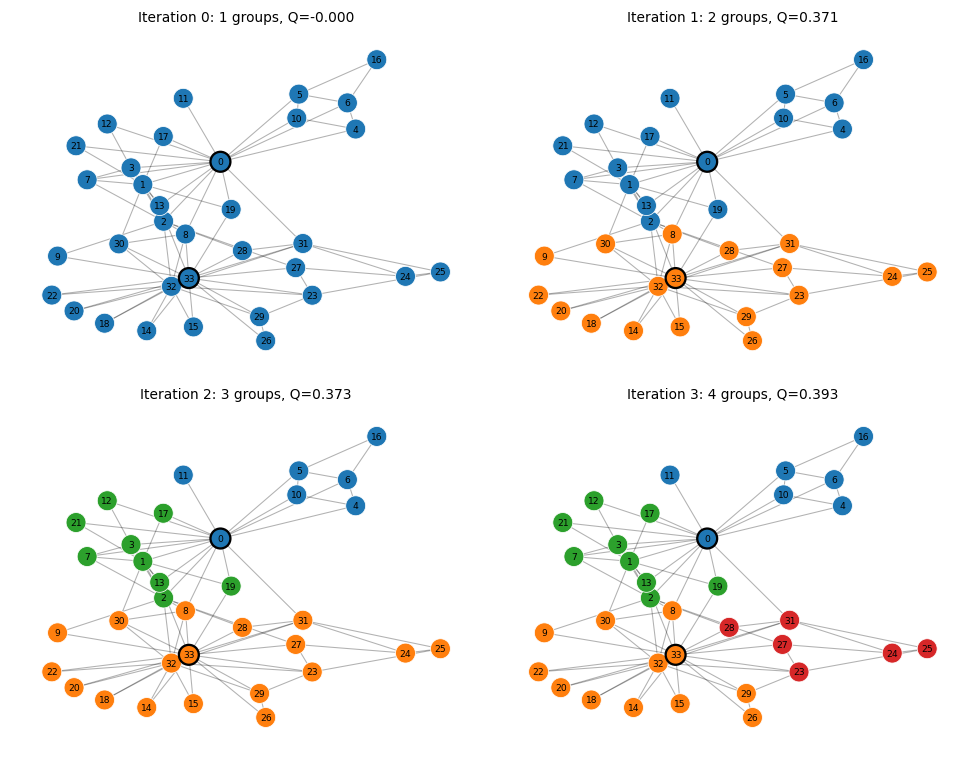

In [ ]:
pos = nx.spring_layout(G, seed=42)
palette = plt.get_cmap("tab10").colors

def draw_partition(labels, title, ax):
    comms = sorted(set(labels))
    colors = [palette[comms.index(labels[i]) % 10] for i in nodes]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.3, width=0.7)
    nx.draw_networkx_nodes(
        G, pos, node_color=colors, node_size=170, ax=ax,
        edgecolors=["black" if i in (0, 33) else "white" for i in nodes],
        linewidths=[1.5 if i in (0, 33) else 0.5 for i in nodes]
    )
    nx.draw_networkx_labels(G, pos, font_size=6, ax=ax)
    ax.set_title(title, fontsize=9)
    ax.axis("off")

fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, h in zip(axes.flat, hist):
    sizes = sorted((int((h["labels"] == c).sum()) for c in set(h["labels"])), reverse=True)
    title = f'Iteration {h["it"]}: {len(sizes)} groups, Q={h["Q"]:.3f}'
    draw_partition(h["labels"], title, ax)
for ax in axes.flat[len(hist):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


### Comparison with the historical split


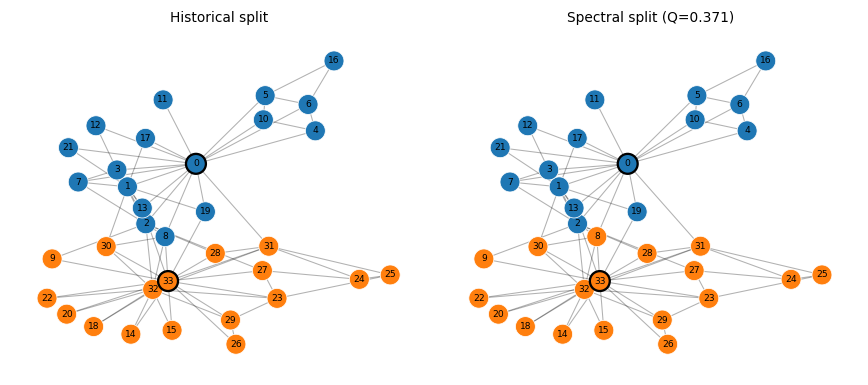

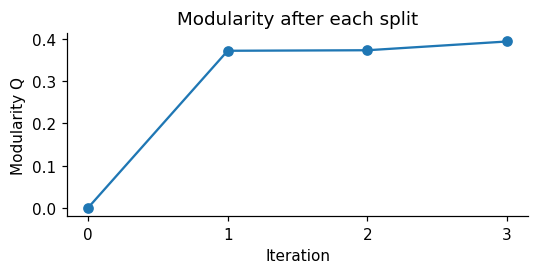

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
draw_partition(truth, "Historical split", axes[0])
draw_partition(hist[1]["labels"], f'Spectral split (Q={hist[1]["Q"]:.3f})', axes[1])
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot([h["it"] for h in hist], [h["Q"] for h in hist], "o-")
ax.set(xlabel="Iteration", ylabel="Modularity Q", title="Modularity after each split")
ax.set_xticks([h["it"] for h in hist])
plt.tight_layout()
plt.show()


## 4. Node metrics

The full-graph metrics do not change between iterations because the edges stay the same. To show how a node's role changes as communities are split, the notebook also calculates metrics on each community's induced subgraph.

The four measures are degree, betweenness, closeness and clustering.


In [ ]:
METRICS = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

def metrics_global(G):
    return {name: f(G) for name, f in METRICS.items()}

def metrics_within(G, labels):
    out = {name: {} for name in METRICS}
    for c in sorted(set(labels)):
        members = [i for i in nodes if labels[i] == c]
        H = G.subgraph(members)                       # induced subgraph of this community
        for name, f in METRICS.items():
            vals = f(H) if H.number_of_nodes() > 1 else {v: 0.0 for v in members}
            out[name].update(vals)
    return out

# dictionaries keyed by iteration number, as requested in the handout
global_metrics = {h["it"]: metrics_global(G) for h in hist}
within_metrics = {h["it"]: metrics_within(G, h["labels"]) for h in hist}

import pandas as pd
def table(d, metric):
    return pd.DataFrame({f"it{it}": pd.Series(d[it][metric]) for it in d}).sort_index()

print("Global metrics are constant across iterations:",
      all(np.allclose(table(global_metrics, mt).values, table(global_metrics, mt).values[:, [0]]) for mt in METRICS))
print("\nWithin-community degree centrality (first 10 nodes):")
table(within_metrics, "Degree centrality").head(10).round(3)

Global metrics are constant across iterations: True

Within-community degree centrality (first 10 nodes):


,it0,it1,it2,it3
0,0.485,0.933,0.833,0.833
1,0.273,0.533,0.875,0.875
2,0.303,0.333,0.500,0.500
3,0.182,0.400,0.625,0.625
4,0.091,0.200,0.500,0.500
5,0.121,0.267,0.667,0.667
6,0.121,0.267,0.667,0.667
7,0.121,0.267,0.375,0.375
8,0.152,0.176,0.176,0.273
9,0.061,0.059,0.059,0.091


## 5. Metric changes

The plots focus on nodes with the highest within-community values, along with the two leaders (0 and 33).


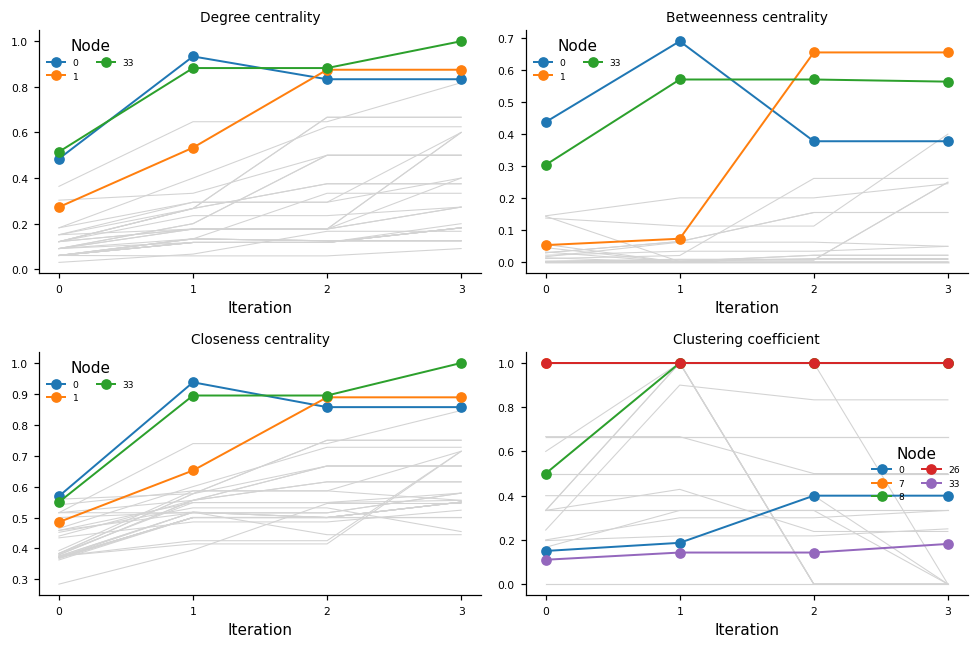

In [ ]:
iters = [h["it"] for h in hist]
HI, OFF = 0, 33

def top_nodes(df, t=3):
    return df.max(axis=1).sort_values(ascending=False).head(t).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, (name, _) in zip(axes.ravel(), METRICS.items()):
    df = table(within_metrics, name)
    highlighted = set(top_nodes(df, 3)) | {HI, OFF}
    for v in nodes:
        if v not in highlighted:
            ax.plot(iters, df.loc[v].values, color="lightgrey", lw=0.7)
    for j, v in enumerate(sorted(highlighted)):
        ax.plot(iters, df.loc[v].values, "o-", lw=1.3,
                color=palette[j % 10], label=str(v))
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Iteration")
    ax.set_xticks(iters)
    ax.tick_params(labelsize=7)
    ax.legend(title="Node", fontsize=6, ncol=2, frameon=False)
plt.tight_layout()
plt.show()


The global values are constant, so the heatmaps show only the within-community metrics.


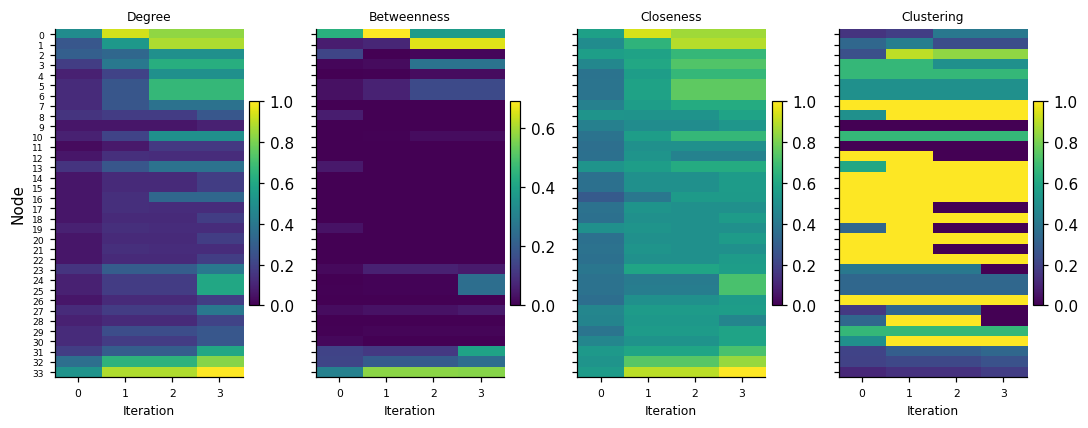

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(10, 4), sharey=True)
for ax, (name, _) in zip(axes, METRICS.items()):
    df = table(within_metrics, name)
    im = ax.imshow(df.values, aspect="auto", cmap="viridis", vmin=0)
    ax.set_title(name.replace(" coefficient", "").replace(" centrality", ""), fontsize=8)
    ax.set_xticks(range(len(iters)))
    ax.set_xticklabels(iters, fontsize=7)
    ax.set_xlabel("Iteration", fontsize=8)
    ax.set_yticks(range(n))
    ax.set_yticklabels(df.index, fontsize=6)
    fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03)
axes[0].set_ylabel("Node")
plt.tight_layout()
plt.show()


In [ ]:
# Average metrics per iteration: how much does community structure change the typical node?
rows = []
for it in iters:
    row = {"iteration": it, "#communities": len(set(hist[it]["labels"])), "Q": round(hist[it]["Q"], 4)}
    for name in METRICS:
        row[f"mean {name.split()[0].lower()}"] = round(np.mean(list(within_metrics[it][name].values())), 4)
    rows.append(row)
pd.DataFrame(rows).set_index("iteration")

,#communities,Q,mean degree,mean betweenness,mean closeness,mean clustering
iteration,,,,,,
0,1,-0.0000,0.1390,0.0440,0.4265,0.5706
1,2,0.3715,0.2505,0.0568,0.5558,0.6836
2,3,0.3727,0.3245,0.0785,0.5878,0.5598
3,4,0.3934,0.3981,0.1024,0.6267,0.5119


In [ ]:
# Who is central? Ranks of the top global nodes, and top-3 within-community nodes per iteration
g = pd.DataFrame({name: pd.Series(global_metrics[0][name]) for name in METRICS})
print("Top 6 nodes by GLOBAL metrics (constant across iterations):")
display_g = g.assign(rank_sum=g[["Degree centrality","Betweenness centrality","Closeness centrality"]].rank(ascending=False).sum(axis=1)).sort_values("rank_sum").head(6)
print(display_g.round(3).to_string())

print("\nTop-3 nodes per iteration by WITHIN-community betweenness and degree:")
for it in iters:
    b = sorted(within_metrics[it]["Betweenness centrality"].items(), key=lambda t: -t[1])[:3]
    d = sorted(within_metrics[it]["Degree centrality"].items(), key=lambda t: -t[1])[:3]
    print(f"  it {it}: betweenness {[(v, round(x,3)) for v,x in b]} | degree {[(v, round(x,3)) for v,x in d]}")

# How many nodes are in each community at the end, and which nodes is each leader with?
final = hist[-1]["labels"]
for c in sorted(set(final)):
    print(f"Community {c}: {[i for i in nodes if final[i]==c]}")

Top 6 nodes by GLOBAL metrics (constant across iterations):
    Degree centrality  Betweenness centrality  Closeness centrality  Clustering coefficient  rank_sum
0               0.485                   0.438                 0.569                   0.150       4.0
33              0.515                   0.304                 0.550                   0.110       6.0
2               0.303                   0.144                 0.559                   0.244      10.0
32              0.364                   0.145                 0.516                   0.197      12.0
31              0.182                   0.138                 0.541                   0.200      15.5
1               0.273                   0.054                 0.485                   0.333      21.0

Top-3 nodes per iteration by WITHIN-community betweenness and degree:
  it 0: betweenness [(0, 0.438), (33, 0.304), (32, 0.145)] | degree [(33, 0.515), (0, 0.485), (32, 0.364)]
  it 1: betweenness [(0, 0.69), (33, 0.57), (32,

## 6. Comparison with the uncorrected matrix

This final check runs the same procedure using the plain restricted block from the handout.


In [ ]:
print("=== Plain block B^(C) = B[C, C] (handout's literal definition) ===")
hist_plain = recursive_spectral_partition(B, m, generalized=False)
print("\nFinal Q  generalised:", round(hist[-1]['Q'], 4), "| plain block:", round(hist_plain[-1]['Q'], 4))
print("Number of communities  generalised:", len(set(hist[-1]['labels'])), "| plain block:", len(set(hist_plain[-1]['labels'])))
def partition_key(labels):
    return sorted(sorted(c) for c in to_sets(labels))
print("Identical final partitions:", partition_key(hist[-1]["labels"]) == partition_key(hist_plain[-1]["labels"]))
for it, h in enumerate(hist_plain):
    pass
print("Reference: networkx greedy modularity Q =",
      round(nx.community.modularity(G, nx.community.greedy_modularity_communities(G)), 4),
      "| Newman's published optimum for this graph is about 0.4198 (4 communities)")

=== Plain block B^(C) = B[C, C] (handout's literal definition) ===
Iter 1: split community 0 (size 34) -> sizes 16 + 18 | lambda1 = 4.9771, dQ = 0.3715, Q = 0.3715
Iter 2: split community 0 (size 16) -> sizes 10 + 6 | lambda1 = 2.9441, dQ = 0.0183, Q = 0.3898
Iter 3: split community 1 (size 18) -> sizes 5 + 13 | lambda1 = 2.5041, dQ = 0.0183, Q = 0.4081
  community of size 10: lambda1 = +2.5712  ->  indivisible (final)
Iter 4: split community 2 (size 6) -> sizes 1 + 5 | lambda1 = 2.1480, dQ = 0.0013, Q = 0.4094
  community of size  5: lambda1 = +1.8759  ->  indivisible (final)
  community of size 13: lambda1 = +2.3563  ->  indivisible (final)
  community of size  1: lambda1 = +0.0000  ->  indivisible (final)
  community of size  5: lambda1 = +2.1470  ->  indivisible (final)

Final Q  generalised: 0.3934 | plain block: 0.4094
Number of communities  generalised: 4 | plain block: 5
Identical final partitions: False
Reference: networkx greedy modularity Q = 0.3807 | Newman's published opti

### What the comparison shows

The first split is the same for both methods because the rows of $B$ sum to zero. Later splits can differ. For the plain block, a positive leading eigenvalue does not always produce a positive modularity gain, so the gain check is still needed.

The plain-block version gives a slightly higher $Q$ on this graph, but that does not make it the correct general method. Both procedures use greedy splits and may stop short of the best possible partition.


## 7. Discussion

The first spectral split matches **33 of the 34 members** in the historical club division. Its modularity is 0.3715. Two further splits produce four communities with $Q=0.3934$.

Nodes 0 and 33 are the main hubs in the full graph. Node 1 becomes an important connector within its community after the first split. This shows why the within-community metrics are useful: the global graph has not changed, but the context around each node has.

Degree and closeness can rise as a community becomes smaller, partly because there are fewer nodes in the subgraph. Betweenness changes more directly with a node's bridging role. Clustering also tends to rise when a node's neighbours are grouped together.

**Limitation:** the method is greedy. It accepts useful splits but does not go back and improve earlier choices, so the final modularity is below the best-known value for this graph.
